In [2]:
from typing import List, TypedDict, Literal
from pydantic import BaseModel, Field

from langchain_community.document_loaders import PyPDFLoader
from langchain_community.vectorstores import FAISS
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_core.documents import Document
from langchain_core.prompts import ChatPromptTemplate

from langgraph.graph import StateGraph, START, END
from dotenv import load_dotenv

In [3]:
load_dotenv()

True

In [4]:
docs = (
    PyPDFLoader("./docs/Company_Profile.pdf").load() + 
    PyPDFLoader("./docs/HR_and_Leave_Policy.pdf").load() + 
    PyPDFLoader("./docs/Products_and_Pricing.pdf").load() + 
    PyPDFLoader("./docs/IT_Security_Policy.pdf").load() + 
    PyPDFLoader("./docs/Customer_Support_and_SLA_Handbook.pdf").load() + 
    PyPDFLoader("./docs/Release_Notes_and_Roadmap.pdf").load() + 
    PyPDFLoader("./docs/Travel_and_Expense_Policy.pdf").load()
)

In [5]:
chunks = RecursiveCharacterTextSplitter(chunk_size=600, chunk_overlap=150).split_documents(docs)

In [6]:
embeddings = HuggingFaceEmbeddings(model_name='sentence-transformers/all-MiniLM-L6-v2')

vector_store = FAISS.from_documents(chunks, embeddings)

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 8871.82it/s]


In [7]:
retriever = vector_store.as_retriever(search_type='similarity', search_kwargs={'k': 4})

In [8]:
llm = ChatGoogleGenerativeAI(model="gemini-3.5-flash-lite")

In [23]:
class State(TypedDict):
    question: str
    need_retrieval: bool

    docs: List[Document]
    relevant_docs: List[Document]

    context: str
    answer: str

    # post-generation verification
    is_answer_supported: Literal["fully_supported", "partially_supported", "not_supported"]
    evidence: List[str]
    
    # prevent infinite loop
    retries: int

    # check usefulness of answer
    is_useful: Literal["useful", "not_useful"]
    use_reason: str
    
    # NEW: if answer not useful then rewrite question and again retrieve
    retrieval_query: str
    rewrite_tries: int

In [24]:
# ============ 1. Decide retrieval =============

class RetrieveDecision(BaseModel):
    should_retrieve: bool = Field(...,description="True if external documents are needed to answer reliably, else False.")


decide_retrieval_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "You decide whether retrieval is needed.\n"
            "Return JSON that matches this schema:\n"
            "{{'should_retrieve': boolean}}\n\n"
            "Guidelines:\n"
            "- should_retrieve=True if answering requires specific facts, citations, or info likely not in the model.\n"
            "- should_retrieve=False for general explanations, definitions, or reasoning that doesn't need sources.\n"
            "- If unsure, choose True."
        ),
        ("human", "Question: {question}"),
    ]
)

should_retrieve_llm = llm.with_structured_output(RetrieveDecision)


def decide_retrieval(state: "State"):
    decision: RetrieveDecision = should_retrieve_llm.invoke(
        decide_retrieval_prompt.format_messages(question=state["question"])
    )
    
    return {"need_retrieval": decision.should_retrieve}

In [25]:
def route_after_decide(state: State) -> Literal["generate_direct", "retrieve"]:
    if state["need_retrieval"]:
        return "retrieve"
    
    return "generate_direct"

In [26]:
# =========== 2. Direct answer (no retrieval) ===========

direct_generation_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "Answer the question using only your general knowledge.\n"
            "Do NOT assume access to external documents.\n"
            "If you are unsure or the answer requires specific sources, say:\n"
            "'I don't know based on my general knowledge.'"
        ),
        ("human", "{question}"),
    ]
)

def generate_direct(state: State):
    out = llm.invoke(
        direct_generation_prompt.format_messages(
            question=state["question"]
        )
    )

    return {"answer": out.content}

In [27]:
# =========== 3. Retrieve (Need Retrieval) =============

def retrieve(state: State):
    return {
        "docs": retriever.invoke(state["question"])
    }

In [28]:
# ============ 4. Relevance filter (check retrieved chunks is relevant or not) ===============

class RelevanceDecision(BaseModel):
    is_relevant: bool = Field(
        ..., description="True ONLY if the document contains info that can directly answer the question."
    )

is_relevant_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "You are judging document relevance at a TOPIC level.\n"
            "Return JSON matching the schema.\n\n"
            "A document is relevant if it discusses the same entity or topic area as the question.\n"
            "It does NOT need to contain the exact answer.\n\n"
            "Examples:\n"
            "- HR policies are relevant to questions about notice period, probation, termination, benefits.\n"
            "- Pricing documents are relevant to questions about refunds, trials, billing terms.\n"
            "- Company profile is relevant to questions about leadership, culture, size, or strategy.\n\n"
            "Do NOT decide whether the document fully answers the question.\n"
            "That will be checked later by is_answer_supported.\n"
            "When unsure, return is_relevant=true."
        ),
        (
            "human",
            "Question:\n{question}\n\nDocument:\n{document}"
        ),
    ]
)

relevance_llm = llm.with_structured_output(RelevanceDecision)


def is_relevant(state: State):
    relevant_docs: List[Document] = []

    for doc in state["docs"]:
        decision: RelevanceDecision = relevance_llm.invoke(
            is_relevant_prompt.format_messages(
                question=state["question"],
                document=doc.page_content
            )
        )

        if decision.is_relevant:
            relevant_docs.append(doc)

    return {"relevant_docs": relevant_docs}

In [29]:
def route_after_relevance(state: State) -> Literal["generate_answer_from_context", "no_relevant_docs"]:
    if state.get("relevant_docs") and len(state["relevant_docs"]) > 0:
        return "generate_answer_from_context"
    
    return "no_relevant_docs"

In [30]:
# =========== 5. Generate answer from context (from relevant retrieved documents) ==============

answer_generation_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "You are a business rag chatbot.\n\n"
            "You will receive a CONTEXT block from internal company documents.\n"
            "Task:\n"
            "Answer the question based on the context"
            "Dont mention that you are getting a context in your answer"
        ),
        (
            "human",
            "Question:\n{question}\n\n"
            "Context:\n{context}\n"
        ),
    ]
)


def generate_answer_from_context(state: State):
    # stuff relevant docs into one
    context = "\n\n----\n\n".join([d.page_content for d in state.get('relevant_docs', [])]).strip()

    if not context:
        return {"answer": "No answer found.", "context": ""}
    
    output = llm.invoke(
        answer_generation_prompt.format_messages(
            question=state["question"],
            context=context
        )
    )
    return {"answer": output.content, "context": context}

In [31]:
# also do web search here
def no_relevant_docs(state: State):
    return {
        "answer": "No answer found.", 
        "context": ""
    }

In [32]:
# ============== 6. is_answer_supported verify + revise loop =================

class IsSupportedDecision(BaseModel):
    is_answer_supported: Literal["fully_supported", "partially_supported", "not_supported"]
    evidence: List[str] = Field(default_factory=list)

check_ans_supported_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "You are verifying whether the ANSWER is supported by the CONTEXT.\n"
            "Return JSON with keys: is_answer_supported, evidence.\n"
            "is_answer_supported must be one of: fully_supported, partially_supported, not_supported.\n\n"
            "How to decide is_answer_supported:\n"
            "- fully_supported:\n"
            "  Every meaningful claim is explicitly supported by CONTEXT, and the ANSWER does NOT introduce\n"
            "  any qualitative/interpretive words that are not present in CONTEXT.\n"
            "  (Examples of disallowed words unless present in CONTEXT: culture, generous, robust, designed to,\n"
            "  supports professional development, best-in-class, employee-first, etc.)\n\n"
            "- partially_supported:\n"
            "  The core facts are supported, BUT the ANSWER includes ANY abstraction, interpretation, or qualitative\n"
            "  phrasing not explicitly stated in CONTEXT (e.g., calling policies 'culture', saying leave is 'generous',\n"
            "  or inferring outcomes like 'supports professional development').\n\n"
            "- no_support:\n"
            "  The key claims are not supported by CONTEXT.\n\n"
            "Rules:\n"
            "- Be strict: if you see ANY unsupported qualitative/interpretive phrasing, choose partially_supported.\n"
            "- If the answer is mostly unrelated to the question or unsupported, choose no_support.\n"
            "- Evidence: include up to 3 short direct quotes from CONTEXT that support the supported parts.\n"
            "- Do not use outside knowledge."
        ),
        (
            "human",
            "Question:\n{question}\n\n"
            "Answer:\n{answer}\n\n"
            "Context:\n{context}\n"
        ),
    ]
)

is_ans_supported_llm = llm.with_structured_output(IsSupportedDecision)


def is_answer_supported(state: State):
    decision: IsSupportedDecision = is_ans_supported_llm.invoke(
        check_ans_supported_prompt.format_messages(
            question = state["question"],
            answer = state.get("answer", ""),
            context = state.get("context", "")
        )
    )

    return {"is_answer_supported": decision.is_answer_supported, "evidence": decision.evidence}


# ============ revise loop ============
MAX_RETRIES = 3

def route_after_isAnsSupp(state: State) -> Literal["accept_answer", "revise_answer"]:
    # accept if fully supported
    if state.get("is_answer_supported") == "fully_supported":
        return "accept_answer"

    # stop if we've already tried enough
    if state.get("retries", 0) >= MAX_RETRIES:
        return "accept_answer"
    
    # otherwise revise again
    return "revise_answer"


def accept_answer(state: State):
    return {}              # keep answer as it is


revise_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "You are a STRICT reviser.\n\n"
            "You must output based on the following format:\n\n"
            "FORMAT (quote-only answer):\n"
            "- <direct quote from the CONTEXT>\n"
            "- <direct quote from the CONTEXT>\n\n"
            "Rules:\n"
            "- Use ONLY the CONTEXT.\n"
            "- Do NOT add any new words besides bullet dashes and the quotes themselves.\n"
            "- Do NOT explain anything.\n"
            "- Do NOT say 'context', 'not mentioned', 'does not mention', 'not provided', etc.\n"
        ),
        (
            "human",
            "Question:\n{question}\n\n"
            "Current Answer:\n{answer}\n\n"
            "CONTEXT:\n{context}"
        ),
    ]
)

def revise_answer(state: State):
    out = llm.invoke(
        revise_prompt.format_messages(
            question=state["question"],
            answer=state.get("answer", ""),
            context=state.get("context", ""),
        )
    )
    return { "answer": out.content, "retries": state.get("retries", 0) + 1 }

In [33]:
# ============== check is_useful answer or not ==============

class IsUSEDecision(BaseModel):
    is_useful: Literal["useful", "not_useful"]
    reason: str = Field(..., description="Short reason in 1 line.")


is_useful_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "You are judging USEFULNESS of the ANSWER for the QUESTION.\n\n"
            "Goal:\n"
            "- Decide if the answer actually addresses what the user asked.\n\n"
            "Return JSON with keys: is_useful, reason.\n"
            "is_useful must be one of: useful, not_useful.\n\n"
            "Rules:\n"
            "- useful: The answer directly answers the question or provides the requested specific info.\n"
            "- not_useful: The answer is generic, off-topic, or only gives related background without answering.\n"
            "- Do NOT use outside knowledge.\n"
            "- Do NOT re-check grounding (is_answer_supported already did that). Only check: 'Did we answer the question?'\n"
            "- Keep reason to 1 short line."
        ),
        (
            "human",
            "Question:\n{question}\n\nAnswer:\n{answer}"
        ),
    ]
)

is_useful_llm = llm.with_structured_output(IsUSEDecision)


def is_useful(state: State):
    decision: IsUSEDecision = is_useful_llm.invoke(
        is_useful_prompt.format_messages(
            question=state["question"],
            answer=state.get("answer", ""),
        )
    )
    return {"is_useful": decision.is_useful, "use_reason": decision.reason}


In [34]:
# ============ Rewrite Question and Again Retrieve ==============

MAX_REWRITE_TRIES = 3

def route_after_isUseful(state: State) -> Literal["END", "rewrite_question" "no_relevant_docs"]:
    if state.get("is_useful") == "useful":
        return "END"
    if state.get("rewrite_tries", 0) >= MAX_REWRITE_TRIES:
        return "no_relevant_docs"
    
    return "rewrite_question"


class RewriteDecision(BaseModel):
    retrieval_query: str = Field(
        ...,
        description="Rewritten query optimized for vector retrieval against internal company PDFs."
    )

rewrite_for_retrieval_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "Rewrite the user's QUESTION into a query optimized for vector retrieval over INTERNAL company PDFs.\n\n"
            "Rules:\n"
            "- Keep it short (6–16 words).\n"
            "- Preserve key entities (e.g., plan names).\n"
            "- Add 2–5 high-signal keywords that likely appear in policy/pricing docs.\n"
            "- Remove filler words.\n"
            "- Do NOT answer the question.\n"
            "- Output JSON with key: retrieval_query\n\n"
        ),
        (
            "human",
            "QUESTION:\n{question}\n\n"
            "Previous retrieval query:\n{retrieval_query}\n\n"
            "Answer (if any):\n{answer}"
        ),
    ]
)

rewrite_llm = llm.with_structured_output(RewriteDecision)

def rewrite_question(state: State):
    decision: RewriteDecision = rewrite_llm.invoke(
        rewrite_for_retrieval_prompt.format_messages(
            question=state["question"],
            retrieval_query=state.get("retrieval_query", ""),
            answer=state.get("answer", ""),
        )
    )

    return {
        "retrieval_query": decision.retrieval_query,
        "rewrite_tries": state.get("rewrite_tries", 0) + 1,
    }

In [36]:
# ========= 7. Build Graph =============
graph = StateGraph(State)

# ========== nodes ==============
graph.add_node("decide_retrieval", decide_retrieval)
graph.add_node("generate_direct", generate_direct)
graph.add_node("retrieve", retrieve)

graph.add_node("is_relevant", is_relevant)
graph.add_node("generate_answer_from_context", generate_answer_from_context)
graph.add_node("is_answer_supported", is_answer_supported)
graph.add_node("revise_answer", revise_answer)
graph.add_node("is_useful", is_useful)

# NEW: rewrite question for better retrieval
graph.add_node("rewrite_question", rewrite_question)

graph.add_node("no_relevant_docs", no_relevant_docs)


# ========= Edges ============
graph.add_edge(START, "decide_retrieval")

graph.add_conditional_edges(
    "decide_retrieval",
    route_after_decide,
    {
        "generate_direct": "generate_direct",
        "retrieve": "retrieve"
    }
)
graph.add_edge("generate_direct", END)
graph.add_edge("retrieve", "is_relevant")

graph.add_conditional_edges(
    "is_relevant",
    route_after_relevance,
    {
        "generate_answer_from_context": "generate_answer_from_context",
        "no_relevant_docs": "no_relevant_docs",
    },
)

# If generated answer from context, verify with is_answer_supported loop
graph.add_edge("generate_answer_from_context", "is_answer_supported")

graph.add_conditional_edges(
    "is_answer_supported",
    route_after_isAnsSupp,
    {
        "accept_answer": "is_useful",       # fully supported goes to is_useful
        "revise_answer": "revise_answer"
    }
)

# revise then re-check is answer supported or not (loop back to is_answer_supported)
graph.add_edge("revise_answer", "is_answer_supported")

# is_useful routing
#   - useful -> END
#   - not_useful -> rewrite_question -> retrieve (try again)
#   - give up -> no_answer_found -> END
graph.add_conditional_edges(
    "is_useful",
    route_after_isUseful,
    {
        "END": END,
        "rewrite_question": "rewrite_question",
        "no_relevant_docs": "no_relevant_docs"
    }
)

# rewrite -> retrieve -> relevance -> ...
graph.add_edge("rewrite_question", "retrieve")

# if no answer found
graph.add_edge("no_relevant_docs", END)

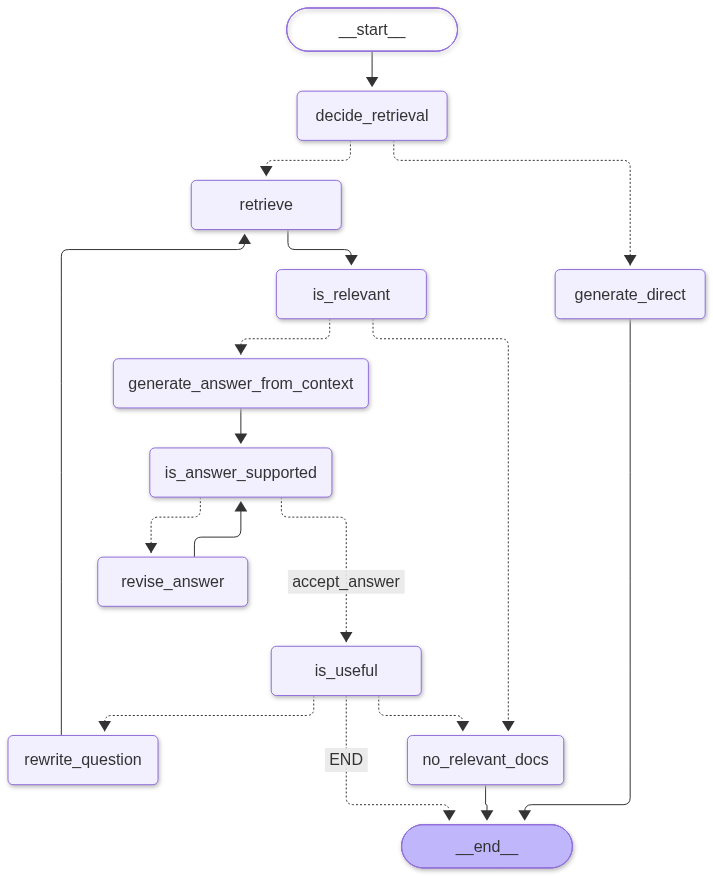

In [37]:
app = graph.compile()

app

In [38]:
initial_state = {
    "question": "What is the minimum password length required by the IT security policy?",
    "need_retrieval": False,
    "docs": [],
    "relevant_docs": [],
    "context": "",
    "answer": "",
    "is_answer_supported": "not_supported",
    "evidence": [],
    "retries": 0,
    "is_useful": "not_useful",
    "use_reason": "",
    "rewrite_tries": 0, 
}

result = app.invoke(
    initial_state, config={"recursion_limit": 50}
)

In [39]:
print("\n======= RAG EXECUTION RESULT ========\n")

print("Question:", result.get("question"))
print("Retrieval required:", result.get("need_retrieval"))
print("Rewrite Question tries (retrieval):", result.get("rewrite_tries", 0))
print("Is Answer Support revise tries:", result.get("retries", 0))

print("\nRetrieval:")
print("   Total documents retrieved:", len(result.get("docs", [])))
print("   Total relevant documents:", len(result.get("relevant_docs", [])))

print("\nVerification (is_answer_supported):")
print("   Answer support status:", result.get("is_answer_supported"))
print("   Evidence:", result.get("evidence"))

print("\nUsefulness:")
print("   Usefulness Status:", result.get("is_useful"))
print("   Usefulness Reason:", result.get("use_reason"))

print("\nFinal answer:", result.get("answer")[0]['text'])


======= RAG EXECUTION RESULT ========

Question: What is the minimum password length required by the IT security policy?
Retrieval required: True
Rewrite Question tries (retrieval): 0
Is Answer Support revise tries: 0

Retrieval:
   Total documents retrieved: 4
   Total relevant documents: 1

Verification (is_answer_supported):
   Answer support status: fully_supported
   Evidence: ['Passwords must have at least 14 characters']

Usefulness:
   Usefulness Status: useful
   Usefulness Reason: The answer directly provides the minimum password length required by the policy.

Final answer: The minimum password length required by the IT security policy is 14 characters.


In [40]:
initial_state = {
    "question": "Does the company offer a good work-life balance?",
    "need_retrieval": False,
    "docs": [],
    "relevant_docs": [],
    "context": "",
    "answer": "",
    "is_answer_supported": "not_supported",
    "evidence": [],
    "retries": 0,
    "is_useful": "not_useful",
    "use_reason": "",
    "rewrite_tries": 0, 
}

result = app.invoke(
    initial_state, config={"recursion_limit": 50}
)

In [42]:
print("\n======= RAG EXECUTION RESULT ========\n")

print("Question:", result.get("question"))
print("Retrieval required:", result.get("need_retrieval"))
print("Rewrite Question tries (retrieval):", result.get("rewrite_tries", 0))
print("Is Answer Support revise tries:", result.get("retries", 0))

print("\nRetrieval:")
print("   Total documents retrieved:", len(result.get("docs", [])))
print("   Total relevant documents:", len(result.get("relevant_docs", [])))

print("\nVerification (is_answer_supported):")
print("   Answer support status:", result.get("is_answer_supported"))
print("   Evidence:", result.get("evidence"))

print("\nUsefulness:")
print("   Usefulness Status:", result.get("is_useful"))
print("   Usefulness Reason:", result.get("use_reason"))

print("\nFinal answer:\n", result.get("answer")[0]['text'])


======= RAG EXECUTION RESULT ========

Question: Does the company offer a good work-life balance?
Retrieval required: True
Rewrite Question tries (retrieval): 0
Is Answer Support revise tries: 1

Retrieval:
   Total documents retrieved: 4
   Total relevant documents: 2

Verification (is_answer_supported):
   Answer support status: fully_supported
   Evidence: ['MFT follows a hybrid model: employees in Pune, Chennai, Dubai and Singapore work from the office on', 'Standard working hours are 9:30 AM to 6:30 PM including a one-hour lunch break.', 'Employees may work fully remotely for up to 20 days per calendar year with manager approval (for']

Usefulness:
   Usefulness Status: useful
   Usefulness Reason: The answer provides specific details about working hours, hybrid model, and remote flexibility, addressing work-life balance.

Final answer:
 - MFT follows a hybrid model: employees in Pune, Chennai, Dubai and Singapore work from the office on
- Standard working hours are 9:30 AM to 6:

In [43]:
initial_state = {
    "question": "Is this company listed on the stock market? Answer only Yes or No.",
    "need_retrieval": False,
    "docs": [],
    "relevant_docs": [],
    "context": "",
    "answer": "",
    "is_answer_supported": "not_supported",
    "evidence": [],
    "retries": 0,
    "is_useful": "not_useful",
    "use_reason": "",
    "rewrite_tries": 0, 
}

result = app.invoke(
    initial_state, config={"recursion_limit": 50}
)

In [49]:
print("\n======= RAG EXECUTION RESULT ========\n")

print("Question:", result.get("question"))
print("Retrieval required:", result.get("need_retrieval"))
print("Rewrite Question tries (retrieval):", result.get("rewrite_tries", 0))
print("Rewritten Question:", result['retrieval_query'])
print("Is Answer Support revise tries:", result.get("retries", 0))

print("\nRetrieval:")
print("   Total documents retrieved:", len(result.get("docs", [])))
print("   Total relevant documents:", len(result.get("relevant_docs", [])))

print("\nVerification (is_answer_supported):")
print("   Answer support status:", result.get("is_answer_supported"))
print("   Evidence:", result.get("evidence"))

print("\nUsefulness:")
print("   Usefulness Status:", result.get("is_useful"))
print("   Usefulness Reason:", result.get("use_reason"))

print("\nFinal answer:\n", result.get("answer")[0]['text'])


======= RAG EXECUTION RESULT ========

Question: Is this company listed on the stock market? Answer only Yes or No.
Retrieval required: True
Rewrite Question tries (retrieval): 1
Rewritten Question: Meridian Freight Technologies Pvt Ltd stock exchange listing public trading shares ticker
Is Answer Support revise tries: 3

Retrieval:
   Total documents retrieved: 4
   Total relevant documents: 2

Verification (is_answer_supported):
   Answer support status: not_supported
   Evidence: []

Usefulness:
   Usefulness Status: useful
   Usefulness Reason: The answer directly provides a Yes or No answer as requested.

Final answer:
 No


In [50]:
initial_state = {
    "question": "How many employees does this company have?",
    "need_retrieval": False,
    "docs": [],
    "relevant_docs": [],
    "context": "",
    "answer": "",
    "is_answer_supported": "not_supported",
    "evidence": [],
    "retries": 0,
    "is_useful": "not_useful",
    "use_reason": "",
    "rewrite_tries": 0,
}

result = app.invoke(
    initial_state, config={"recursion_limit": 50}
)

In [53]:
print("\n======= RAG EXECUTION RESULT ========\n")

print("Question:", result.get("question"))
print("Retrieval required:", result.get("need_retrieval"))
print("Rewrite Question tries (retrieval):", result.get("rewrite_tries", 0))
print("Rewritten Question:", result.get("retrieval_query", ""))
print("Is Answer Support revise tries:", result.get("retries", 0))

print("\nRetrieval:")
print("   Total documents retrieved:", len(result.get("docs", [])))
print("   Total relevant documents:", len(result.get("relevant_docs", [])))

print("\nVerification (is_answer_supported):")
print("   Answer support status:", result.get("is_answer_supported"))
print("   Evidence:", result.get("evidence"))

print("\nUsefulness:")
print("   Usefulness Status:", result.get("is_useful"))
print("   Usefulness Reason:", result.get("use_reason"))

print("\nFinal answer:\n", result.get("answer"))


======= RAG EXECUTION RESULT ========

Question: How many employees does this company have?
Retrieval required: True
Rewrite Question tries (retrieval): 0
Rewritten Question: 
Is Answer Support revise tries: 0

Retrieval:
   Total documents retrieved: 4
   Total relevant documents: 0

Verification (is_answer_supported):
   Answer support status: not_supported
   Evidence: []

Usefulness:
   Usefulness Status: not_useful
   Usefulness Reason: 

Final answer:
 No answer found.
